<a href="https://colab.research.google.com/github/luisy-eng/ECE491_Lab3/blob/main/ECE4_Lab3_BackdoorBox_Upload_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECE4 Lab 3 — BackdoorBox



## 1. Check runtime

In [1]:
import sys, torch
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 2. Upload `BackdoorBox-main.zip`

Click **Choose Files** and select the ZIP you downloaded from GitHub. If your Colab session restarts, run the upload cell again (or save the ZIP in Google Drive).

In [2]:
from google.colab import files
uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload exactly one repository ZIP file."
zip_name = zip_names[0]
print("Uploaded:", zip_name)

Saving BackdoorBox-main.zip to BackdoorBox-main.zip
Uploaded: BackdoorBox-main.zip


## 3. Extract to `/content/BackdoorBox-main`

In [3]:
from pathlib import Path
import zipfile
import shutil

root = Path("/content")
project = root / "BackdoorBox-main"
if project.exists():
    shutil.rmtree(project)

with zipfile.ZipFile(zip_name) as z:
    members = z.namelist()
    assert all(not Path(m).is_absolute() and ".." not in Path(m).parts for m in members), "Unsafe ZIP paths"
    z.extractall(root)

assert (project / "core" / "__init__.py").exists(), "Expected BackdoorBox-main/core not found. Check ZIP layout."
print("Extracted:", project)
print("Attack samples:", [p.name for p in sorted((project / "core" / "attacks").glob("*.py")) if p.name in ("BadNets.py", "Blended.py", "LabelConsistent.py")])

Extracted: /content/BackdoorBox-main
Attack samples: ['BadNets.py', 'Blended.py', 'LabelConsistent.py']


## 4. Install baseline libraries without downgrading Colab PyTorch

**Do not run `pip install -r requirements.txt`**. This repository pins PyTorch 1.8.0 and CUDA 11.1, which are incompatible with current Colab runtimes. Its `core` imports may also require more optional packages; we will diagnose these after the baseline setup.

In [4]:
%pip -q install lpips imageio matplotlib scikit-learn pandas opencv-python-headless

## 5. Set Python path and inspect framework imports

In [5]:
import os, sys, importlib, traceback
os.chdir(project)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
print("Working directory:", os.getcwd())

try:
    import core
    print("BackdoorBox core imported successfully")
    for name in ("BadNets", "Blended", "LabelConsistent", "FineTuning", "Pruning"):
        print(f"{name}: {hasattr(core, name)}")
except Exception as exc:
    print("BackdoorBox import requires compatibility work:")
    print(type(exc).__name__ + ":", exc)
    print("This does not mean your upload failed. Save the full error for the next step.")
    traceback.print_exc(limit=5)

Working directory: /content/BackdoorBox-main
BackdoorBox import requires compatibility work:
ImportError: cannot import name 'zero_gradients' from 'torch.autograd.gradcheck' (/usr/local/lib/python3.13/dist-packages/torch/autograd/gradcheck.py)
This does not mean your upload failed. Save the full error for the next step.


/content/BackdoorBox-main/core/attacks/Blind.py:209: SyntaxWarning: invalid escape sequence '\s'
  ie. min_c |\sum c_i x_i|_2^2 st. \sum c_i = 1 , 1 >= c_1 >= 0
/content/BackdoorBox-main/core/attacks/Blind.py:243: SyntaxWarning: invalid escape sequence '\s'
  Given y, it solves argmin_z |y-z|_2 st \sum z = 1 , 1 >= z_i >= 0 for all i
/content/BackdoorBox-main/core/attacks/Blind.py:278: SyntaxWarning: invalid escape sequence '\s'
  element in the convex hull as min |u|_2 st. u = \sum c_i vecs[i]
/content/BackdoorBox-main/core/attacks/Blind.py:333: SyntaxWarning: invalid escape sequence '\s'
  as min |u|_2 st. u = \sum c_i vecs[i] and \sum c_i = 1.
Traceback (most recent call last):
  File "/tmp/ipykernel_2686/949600075.py", line 8, in <cell line: 0>
    import core
  File "/content/BackdoorBox-main/core/__init__.py", line 1, in <module>
    from .attacks import *
  File "/content/BackdoorBox-main/core/attacks/__init__.py", line 12, in <module>
    from .TUAP import TUAP
  File "/content

## 6. Load CIFAR-10 with torchvision

This creates the official training and testing datasets under `/content/data`. We will use a single consistent split for the attack comparisons.

In [6]:
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()
trainset = datasets.CIFAR10(root="/content/data", train=True, download=True, transform=transform)
testset = datasets.CIFAR10(root="/content/data", train=False, download=True, transform=transform)
print("Train images:", len(trainset))
print("Test images:", len(testset))
print("Class labels:", trainset.classes)

100%|██████████| 170M/170M [31:49<00:00, 89.3kB/s]


Train images: 50000
Test images: 10000
Class labels: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 7. Display clean CIFAR-10 samples

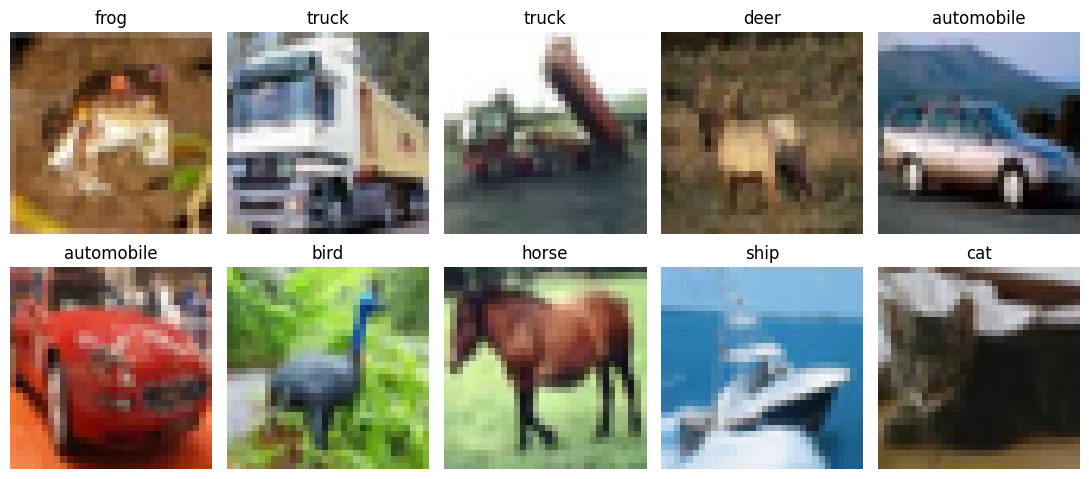

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    image, label = trainset[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(trainset.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Verify provided experiment scripts

The repository contains `Attack_BadNets.py`, `Attack_Blended.py`, and tests for `LabelConsistent`, `FineTuning`, and `Pruning`. The top-level scripts expect a folder-organized CIFAR-10 dataset, while our direct torchvision loading is simpler. We will adapt the actual experiment code after checking imports.

In [8]:
for relative in ["Attack_BadNets.py", "Attack_Blended.py", "tests/test_LabelConsistent.py", "tests/test_FineTuning.py", "tests/test_Pruning.py"]:
    p = project / relative
    print(("FOUND" if p.exists() else "MISSING"), relative)

FOUND Attack_BadNets.py
FOUND Attack_Blended.py
FOUND tests/test_LabelConsistent.py
FOUND tests/test_FineTuning.py
FOUND tests/test_Pruning.py


# Task 1 — BadNets


In [10]:
from pathlib import Path

file = Path("/content/BackdoorBox-main/core/attacks/TUAP.py")

code = file.read_text()

old = "from torch.autograd.gradcheck import zero_gradients"

new = """
def zero_gradients(x):
    if isinstance(x, torch.Tensor):
        if x.grad is not None:
            x.grad.detach_()
            x.grad.zero_()
    else:
        for item in x:
            zero_gradients(item)
"""

import torch

if old in code:
    code = code.replace(old, new)
    file.write_text(code)
    print("TUAP.py compatibility patch applied!")
else:
    print("Old import not found; file may already be patched.")

TUAP.py compatibility patch applied!


In [12]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

from core.attacks.BadNets import BadNets

print("BadNets import successful!")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU: Tesla T4
BadNets import successful!


#Step 1 — Define the BadNets trigger

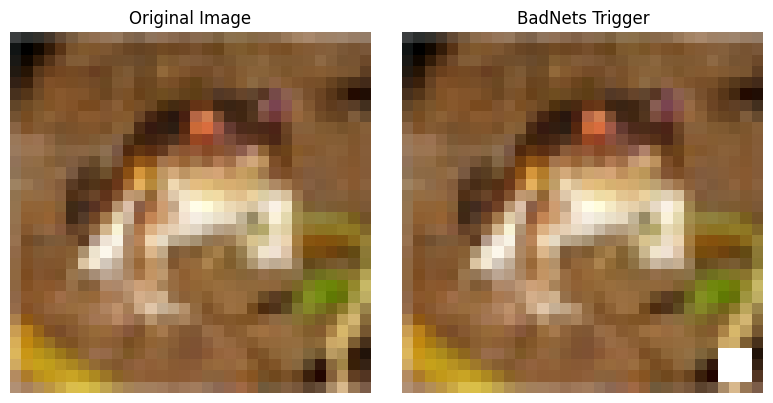

In [13]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Load CIFAR-10
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

# Define a 3x3 white-square trigger
def add_badnets_trigger(image):
    poisoned = image.clone()
    poisoned[:, -4:-1, -4:-1] = 1.0
    return poisoned

# Select a sample image
image, label = train_dataset[0]
poisoned_image = add_badnets_trigger(image)

# Display clean and poisoned images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image.permute(1, 2, 0))
axes[0].set_title("Original Image")

axes[1].imshow(poisoned_image.permute(1, 2, 0))
axes[1].set_title("BadNets Trigger")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("badnets_sample.png", dpi=300)
plt.show()


#Step 2 — Create the poisoned dataset using BackdoorBox

In [15]:

import random
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from core.attacks.BadNets import BadNets

# Reproducibility
random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load CIFAR-10 training and test datasets
# BackdoorBox requires transforms.Compose()
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.CIFAR10(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

# Define the BadNets trigger (3x3 white square)
pattern = torch.zeros((1, 32, 32), dtype=torch.uint8)
pattern[:, -4:-1, -4:-1] = 255

weight = torch.zeros((1, 32, 32), dtype=torch.float32)
weight[:, -4:-1, -4:-1] = 1.0

# CIFAR-10 adapted ResNet-18
model = models.resnet18(weights=None)

model.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)

model.maxpool = nn.Identity()
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

# Configure the BadNets attack
attack = BadNets(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model,
    loss=nn.CrossEntropyLoss(),
    y_target=0,
    poisoned_rate=0.10,
    pattern=pattern,
    weight=weight,
    poisoned_transform_train_index=0,
    poisoned_transform_test_index=0,
    poisoned_target_transform_index=0,
    seed=42
)

# Retrieve poisoned datasets
poisoned_train = attack.poisoned_train_dataset
poisoned_test = attack.poisoned_test_dataset

# Verify configuration
print("Device:", device)
print("Training images:", len(poisoned_train))
print("Poisoned training images:", len(poisoned_train.poisoned_set))
print("Test images:", len(poisoned_test))
print("Target class:", train_dataset.classes[0])


Device: cuda
Training images: 50000
Poisoned training images: 5000
Test images: 10000
Target class: airplane


#Step 3 — Visualize the poisoned training dataset


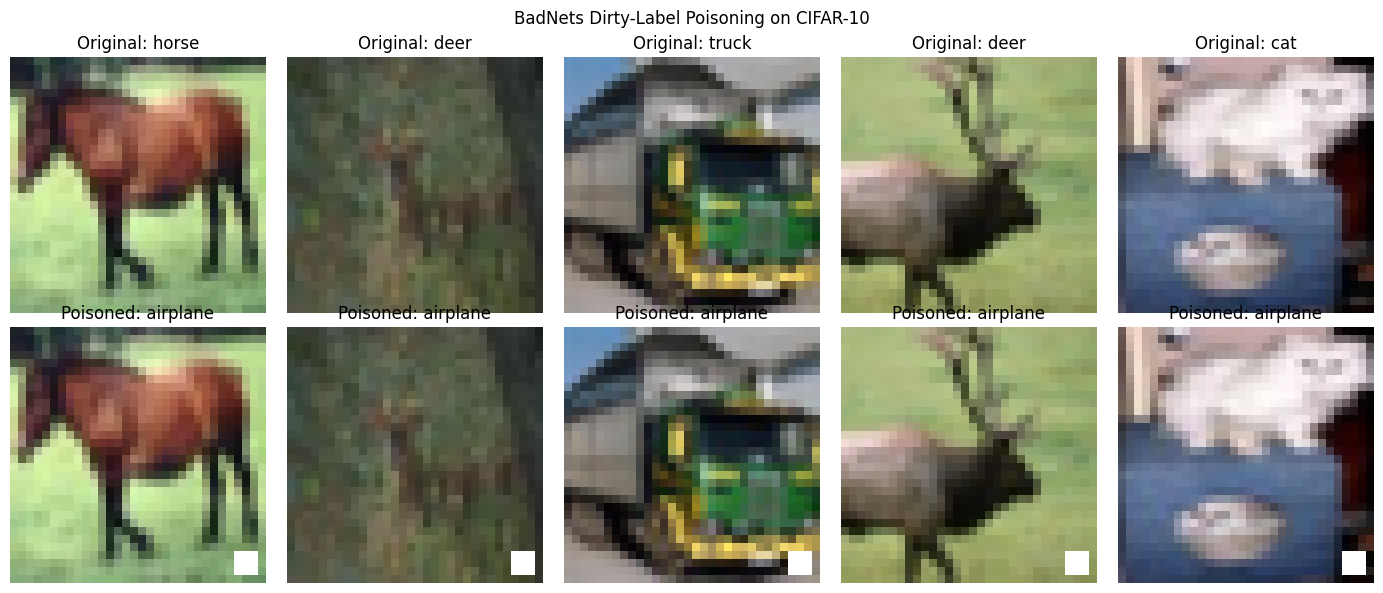

In [16]:

import matplotlib.pyplot as plt

# Select five poisoned samples from non-target classes
indices = [
    i for i in sorted(poisoned_train.poisoned_set)
    if train_dataset.targets[i] != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for j, idx in enumerate(indices):
    clean_img, clean_label = train_dataset[idx]
    poisoned_img, poisoned_label = poisoned_train[idx]

    # Original image
    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"Original: {train_dataset.classes[clean_label]}"
    )

    # Poisoned image
    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Poisoned: {train_dataset.classes[poisoned_label]}"
    )

    # Verify that the label changed to airplane
    assert poisoned_label == 0

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Poisoned", fontsize=12)

plt.suptitle("BadNets Dirty-Label Poisoning on CIFAR-10")
plt.tight_layout()
plt.savefig("badnets_poisoned_dataset.png", dpi=300)
plt.show()


#Step 4 — Train ResNet-18 using the poisoned dataset


In [17]:

from torch.utils.data import DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path

# Create output folder
output_dir = Path("/content/badnets_results")
output_dir.mkdir(parents=True, exist_ok=True)

# Training configuration
EPOCHS = 15
BATCH_SIZE = 128
LEARNING_RATE = 0.01

train_loader = DataLoader(
    poisoned_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

clean_test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

criterion = nn.CrossEntropyLoss()

history = {
    "train_loss": [],
    "train_accuracy": [],
    "clean_accuracy": []
}

# Evaluation function
@torch.no_grad()
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total

# Training loop
for epoch in range(EPOCHS):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100.0 * correct / total
    clean_accuracy = evaluate_accuracy(model, clean_test_loader)

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["clean_accuracy"].append(clean_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Clean Accuracy: {clean_accuracy:.2f}%"
    )

    # Save checkpoint each epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history
    }, output_dir / "badnets_checkpoint.pth")

# Save final model
torch.save(
    model.state_dict(),
    output_dir / "badnets_resnet18.pth"
)

print("Training completed. Model saved.")


Epoch 01/15 | Loss: 1.3724 | Train Accuracy: 49.35% | Clean Accuracy: 40.76%
Epoch 02/15 | Loss: 0.8872 | Train Accuracy: 68.41% | Clean Accuracy: 52.24%
Epoch 03/15 | Loss: 0.6389 | Train Accuracy: 77.48% | Clean Accuracy: 64.28%
Epoch 04/15 | Loss: 0.4485 | Train Accuracy: 84.49% | Clean Accuracy: 67.16%
Epoch 05/15 | Loss: 0.2686 | Train Accuracy: 90.85% | Clean Accuracy: 70.61%
Epoch 06/15 | Loss: 0.1281 | Train Accuracy: 95.90% | Clean Accuracy: 71.82%
Epoch 07/15 | Loss: 0.0451 | Train Accuracy: 98.85% | Clean Accuracy: 75.88%
Epoch 08/15 | Loss: 0.0131 | Train Accuracy: 99.80% | Clean Accuracy: 77.49%
Epoch 09/15 | Loss: 0.0038 | Train Accuracy: 99.99% | Clean Accuracy: 78.27%
Epoch 10/15 | Loss: 0.0022 | Train Accuracy: 100.00% | Clean Accuracy: 78.46%
Epoch 11/15 | Loss: 0.0017 | Train Accuracy: 100.00% | Clean Accuracy: 78.44%
Epoch 12/15 | Loss: 0.0015 | Train Accuracy: 100.00% | Clean Accuracy: 78.50%
Epoch 13/15 | Loss: 0.0015 | Train Accuracy: 100.00% | Clean Accuracy: 78

#Step 5 — Plot the training results

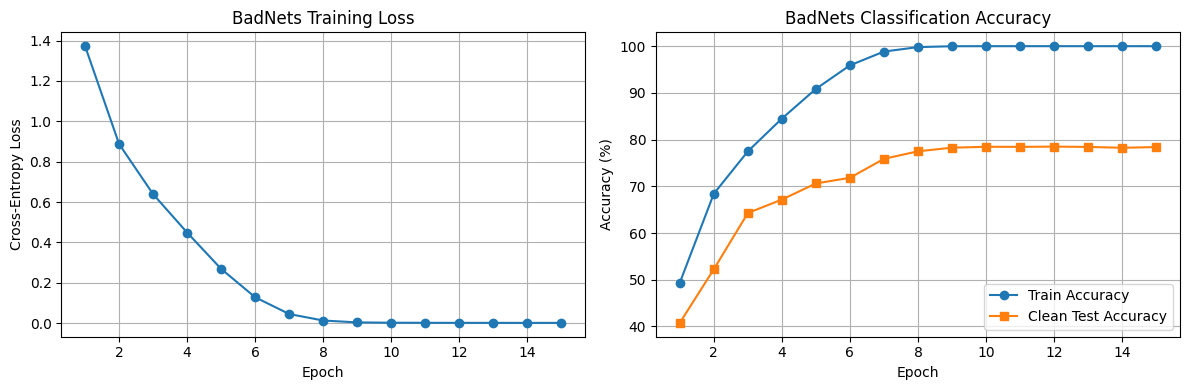

In [19]:

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o")
axes[0].set_title("BadNets Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs,
    history["clean_accuracy"],
    marker="s",
    label="Clean Test Accuracy"
)
axes[1].set_title("BadNets Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    output_dir / "badnets_training_curves.png",
    dpi=300
)
plt.show()

#Step 6 — Evaluate BadNets Attack Success Rate (ASR)

In [20]:

from torch.utils.data import DataLoader
import torch
import json

# Evaluate the poisoned test dataset
poisoned_test_loader = DataLoader(
    poisoned_test,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

TARGET_CLASS = 0

model.eval()

successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(
        poisoned_test_loader
    ):
        # Recover the original labels from the clean dataset
        start = batch_idx * 128
        end = start + len(labels)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        # Exclude images originally belonging to target class
        mask = original_labels != TARGET_CLASS

        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        successful_attacks += (
            predictions == TARGET_CLASS
        ).sum().item()

        total_attacks += images.size(0)

asr = 100.0 * successful_attacks / total_attacks

clean_accuracy = evaluate_accuracy(
    model,
    clean_test_loader
)

print("=" * 45)
print("BadNets Evaluation Results")
print("=" * 45)
print(f"Clean Accuracy: {clean_accuracy:.2f}%")
print(f"Attack Success Rate: {asr:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Samples: {total_attacks}")
print("=" * 45)

# Save results
results = {
    "attack": "BadNets",
    "dataset": "CIFAR-10",
    "model": "ResNet-18",
    "poison_rate": 0.10,
    "target_class": "airplane",
    "epochs": 15,
    "clean_accuracy": clean_accuracy,
    "attack_success_rate": asr
}

with open(output_dir / "badnets_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results saved successfully.")


BadNets Evaluation Results
Clean Accuracy: 78.40%
Attack Success Rate: 97.32%
Successful Attacks: 8759
Total Attack Samples: 9000
Results saved successfully.


#Step 7 — Create the final BadNets attack demonstration

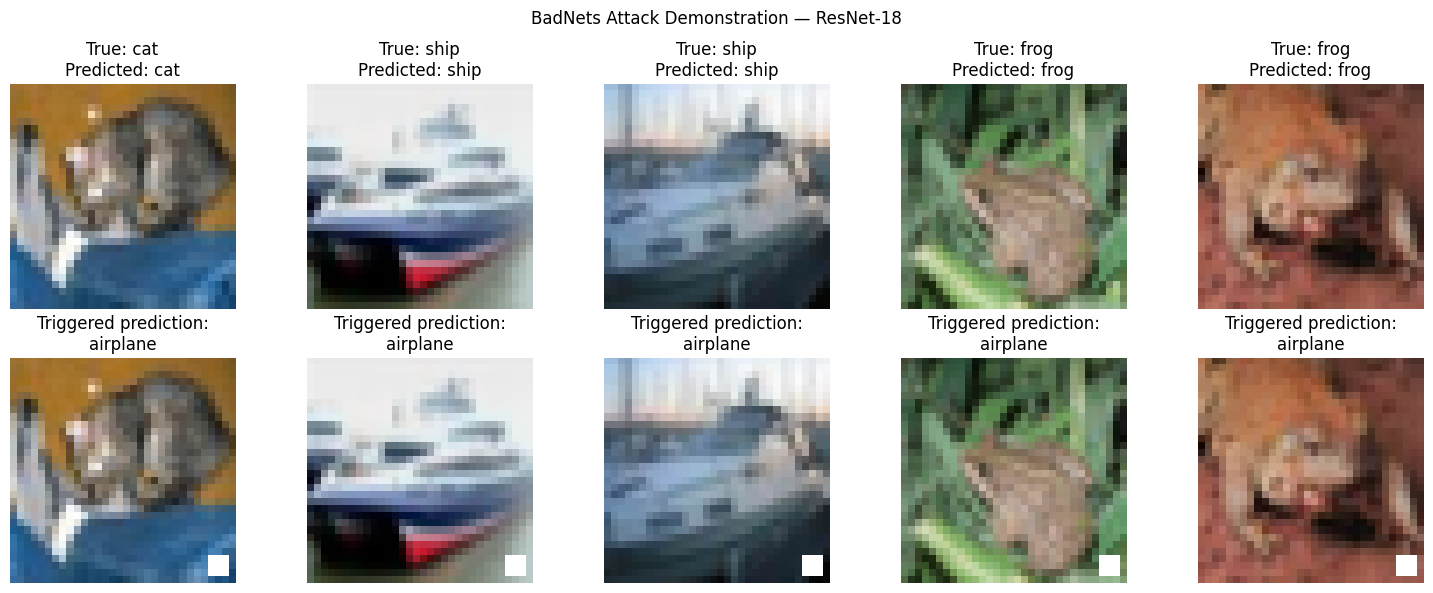

In [21]:

import matplotlib.pyplot as plt
import torch

model.eval()

# Choose five test images that are not airplanes
indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, idx in enumerate(indices):
    clean_img, true_label = test_dataset[idx]
    poisoned_img, _ = poisoned_test[idx]

    with torch.no_grad():
        clean_pred = model(
            clean_img.unsqueeze(0).to(device)
        ).argmax(1).item()

        poison_pred = model(
            poisoned_img.unsqueeze(0).to(device)
        ).argmax(1).item()

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Predicted: {test_dataset.classes[clean_pred]}"
    )

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Triggered prediction:\n"
        f"{test_dataset.classes[poison_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("BadNets Attack Demonstration — ResNet-18")
plt.tight_layout()

plt.savefig(
    output_dir / "badnets_attack_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Task 1B — Blended Dirty-Label Attack

In [22]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision import models
from core.attacks.Blended import Blended

# Save Blended results separately
blended_dir = Path("/content/blended_results")
blended_dir.mkdir(parents=True, exist_ok=True)

# Confirm BadNets checkpoint exists
badnets_path = Path(
    "/content/badnets_results/badnets_resnet18.pth"
)
assert badnets_path.exists(), "Save BadNets before proceeding."

# Blended trigger: checkerboard pattern
# Values are in the 0-255 pixel range
pattern_blended = torch.zeros(
    (3, 32, 32), dtype=torch.uint8
)

for row in range(32):
    for col in range(32):
        if ((row // 4) + (col // 4)) % 2 == 0:
            pattern_blended[:, row, col] = 255

# Blend 20% pattern with 80% original image
ALPHA = 0.20
weight_blended = torch.full(
    (3, 32, 32), ALPHA, dtype=torch.float32
)

# Initialize a fresh ResNet-18
model_blended = models.resnet18(weights=None)
model_blended.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)
model_blended.maxpool = nn.Identity()
model_blended.fc = nn.Linear(
    model_blended.fc.in_features, 10
)
model_blended = model_blended.to(device)

# Configure BackdoorBox Blended
attack_blended = Blended(
    train_dataset=train_dataset,
    test_dataset=test_dataset,
    model=model_blended,
    loss=nn.CrossEntropyLoss(),
    y_target=0,
    poisoned_rate=0.10,
    pattern=pattern_blended,
    weight=weight_blended,
    poisoned_transform_train_index=0,
    poisoned_transform_test_index=0,
    poisoned_target_transform_index=0,
    seed=42
)

blended_train = attack_blended.poisoned_train_dataset
blended_test = attack_blended.poisoned_test_dataset

print("Blended attack initialized!")
print("Training images:", len(blended_train))
print("Poisoned images:", len(blended_train.poisoned_set))
print("Test images:", len(blended_test))
print("Blending factor:", ALPHA)
print("Target class:", train_dataset.classes[0])


Blended attack initialized!
Training images: 50000
Poisoned images: 5000
Test images: 10000
Blending factor: 0.2
Target class: airplane


#Step 2 — Visualize the Blended poisoned images

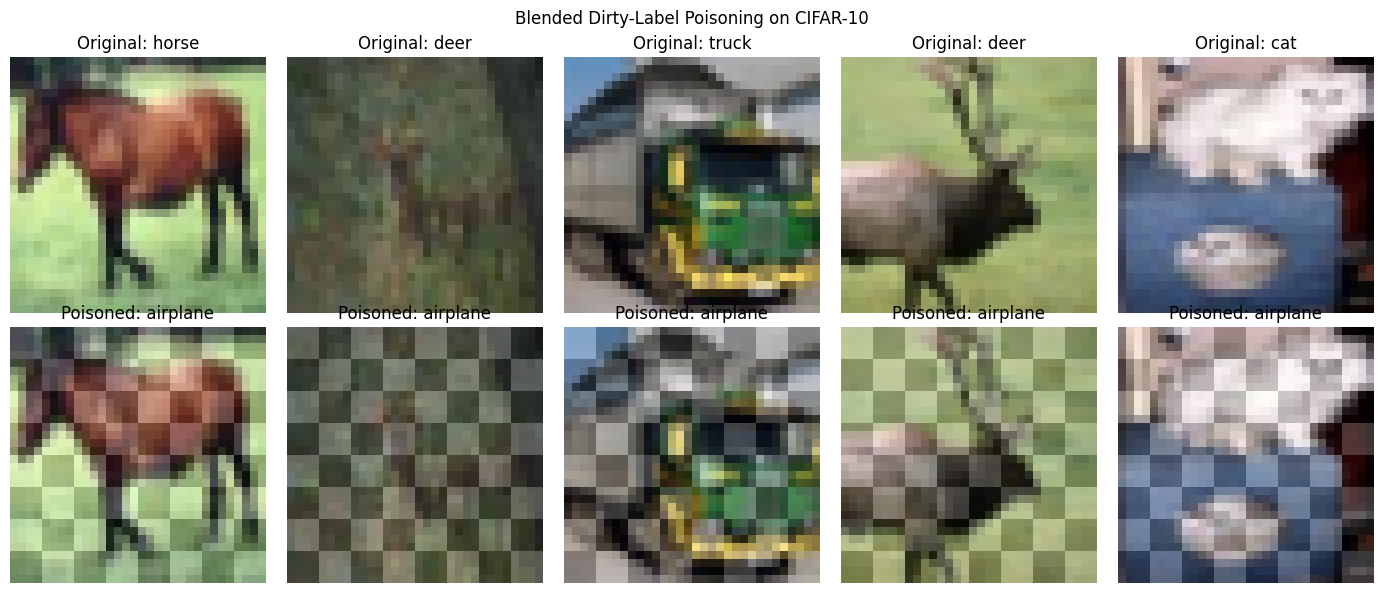

In [23]:

indices = [
    i for i in sorted(blended_train.poisoned_set)
    if train_dataset.targets[i] != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for j, idx in enumerate(indices):
    clean_img, clean_label = train_dataset[idx]
    poisoned_img, poisoned_label = blended_train[idx]

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"Original: {train_dataset.classes[clean_label]}"
    )

    axes[1, j].imshow(
        poisoned_img.permute(1, 2, 0)
    )
    axes[1, j].set_title(
        f"Poisoned: {train_dataset.classes[poisoned_label]}"
    )

    assert poisoned_label == 0

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Blended Dirty-Label Poisoning on CIFAR-10")
plt.tight_layout()

plt.savefig(
    blended_dir / "blended_poisoned_dataset.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#Step 3 — Train the Blended model

In [24]:

from torch.utils.data import DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt
import json

EPOCHS = 15
BATCH_SIZE = 128

blended_loader = DataLoader(
    blended_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

optimizer_blended = optim.SGD(
    model_blended.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler_blended = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_blended,
    T_max=EPOCHS
)

criterion = nn.CrossEntropyLoss()

blended_history = {
    "train_loss": [],
    "train_accuracy": [],
    "clean_accuracy": []
}

for epoch in range(EPOCHS):
    model_blended.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in blended_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_blended.zero_grad(set_to_none=True)

        outputs = model_blended(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_blended.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    clean_acc = evaluate_accuracy(
        model_blended,
        clean_test_loader
    )

    scheduler_blended.step()

    blended_history["train_loss"].append(train_loss)
    blended_history["train_accuracy"].append(train_acc)
    blended_history["clean_accuracy"].append(clean_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Train: {train_acc:.2f}% | "
        f"Clean: {clean_acc:.2f}%"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_blended.state_dict(),
        "optimizer_state_dict": optimizer_blended.state_dict(),
        "history": blended_history
    }, blended_dir / "blended_checkpoint.pth")

torch.save(
    model_blended.state_dict(),
    blended_dir / "blended_resnet18.pth"
)

print("Blended training complete!")


Epoch 01/15 | Loss: 1.3335 | Train: 50.83% | Clean: 45.65%
Epoch 02/15 | Loss: 0.8660 | Train: 69.02% | Clean: 65.41%
Epoch 03/15 | Loss: 0.6159 | Train: 78.20% | Clean: 66.88%
Epoch 04/15 | Loss: 0.4317 | Train: 84.97% | Clean: 70.50%
Epoch 05/15 | Loss: 0.2614 | Train: 91.08% | Clean: 69.37%
Epoch 06/15 | Loss: 0.1284 | Train: 95.89% | Clean: 74.26%
Epoch 07/15 | Loss: 0.0482 | Train: 98.64% | Clean: 74.60%
Epoch 08/15 | Loss: 0.0121 | Train: 99.82% | Clean: 78.76%
Epoch 09/15 | Loss: 0.0034 | Train: 100.00% | Clean: 79.79%
Epoch 10/15 | Loss: 0.0020 | Train: 100.00% | Clean: 79.98%
Epoch 11/15 | Loss: 0.0016 | Train: 100.00% | Clean: 80.04%
Epoch 12/15 | Loss: 0.0015 | Train: 100.00% | Clean: 80.09%
Epoch 13/15 | Loss: 0.0014 | Train: 100.00% | Clean: 79.96%
Epoch 14/15 | Loss: 0.0013 | Train: 100.00% | Clean: 80.01%
Epoch 15/15 | Loss: 0.0013 | Train: 100.00% | Clean: 79.94%
Blended training complete!


#Step 4 — Plot training curves

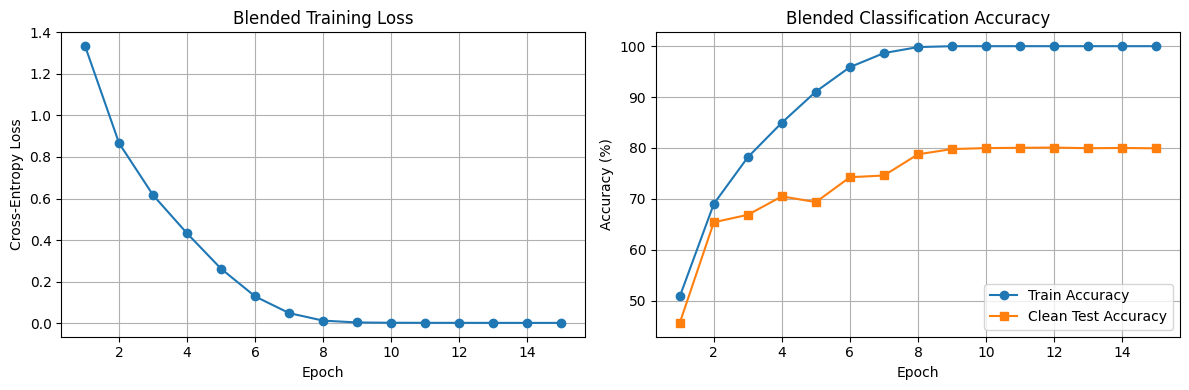

In [25]:

epochs = range(1, len(blended_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs,
    blended_history["train_loss"],
    marker="o"
)
axes[0].set_title("Blended Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)

axes[1].plot(
    epochs,
    blended_history["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)
axes[1].plot(
    epochs,
    blended_history["clean_accuracy"],
    marker="s",
    label="Clean Test Accuracy"
)

axes[1].set_title("Blended Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    blended_dir / "blended_training_curves.png",
    dpi=300
)
plt.show()


#Step 5 — Evaluate Blended attack success rate

In [26]:

blended_test_loader = DataLoader(
    blended_test,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

model_blended.eval()

successful_attacks = 0
total_attacks = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(blended_test_loader):
        start = batch_idx * 128
        end = start + len(labels)

        original_labels = torch.tensor(
            test_dataset.targets[start:end]
        )

        mask = original_labels != 0
        images = images[mask].to(device)

        if images.size(0) == 0:
            continue

        predictions = model_blended(images).argmax(1)

        successful_attacks += (
            predictions == 0
        ).sum().item()

        total_attacks += images.size(0)

blended_asr = 100 * successful_attacks / total_attacks
blended_ca = evaluate_accuracy(
    model_blended,
    clean_test_loader
)

print("=" * 45)
print("Blended Attack Evaluation Results")
print("=" * 45)
print(f"Clean Accuracy: {blended_ca:.2f}%")
print(f"Attack Success Rate: {blended_asr:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Samples: {total_attacks}")

blended_results = {
    "attack": "Blended",
    "dataset": "CIFAR-10",
    "model": "ResNet-18",
    "poison_rate": 0.10,
    "alpha": ALPHA,
    "target_class": "airplane",
    "epochs": 15,
    "clean_accuracy": blended_ca,
    "attack_success_rate": blended_asr
}

with open(blended_dir / "blended_results.json", "w") as f:
    json.dump(blended_results, f, indent=4)

print("Blended results saved successfully.")


Blended Attack Evaluation Results
Clean Accuracy: 79.94%
Attack Success Rate: 100.00%
Successful Attacks: 9000
Total Attack Samples: 9000
Blended results saved successfully.


#Step 6 — Generate the Blended attack demonstration

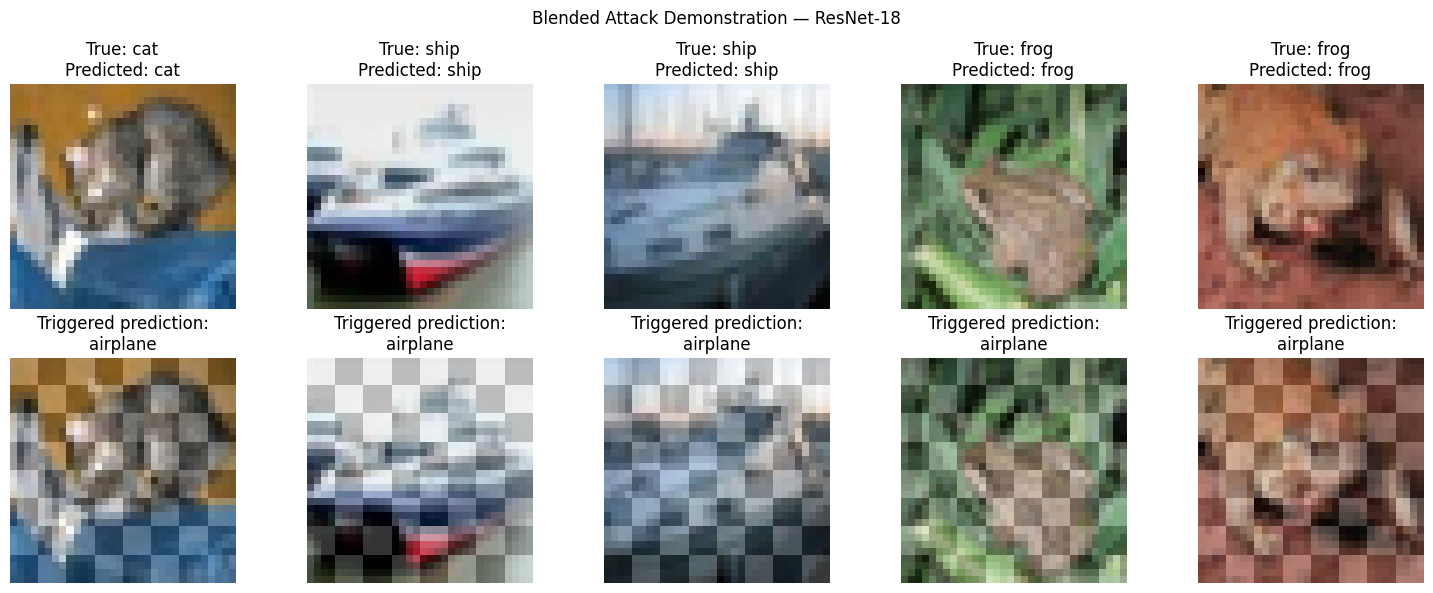

In [27]:

import matplotlib.pyplot as plt
import torch

model_blended.eval()

# Select five non-target test images
indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label != 0
][:5]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for j, idx in enumerate(indices):
    clean_img, true_label = test_dataset[idx]
    poisoned_img, _ = blended_test[idx]

    with torch.no_grad():
        clean_pred = model_blended(
            clean_img.unsqueeze(0).to(device)
        ).argmax(1).item()

        poison_pred = model_blended(
            poisoned_img.unsqueeze(0).to(device)
        ).argmax(1).item()

    axes[0, j].imshow(clean_img.permute(1, 2, 0))
    axes[0, j].set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Predicted: {test_dataset.classes[clean_pred]}"
    )

    axes[1, j].imshow(poisoned_img.permute(1, 2, 0))
    axes[1, j].set_title(
        f"Triggered prediction:\n"
        f"{test_dataset.classes[poison_pred]}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Blended Attack Demonstration — ResNet-18")
plt.tight_layout()

plt.savefig(
    blended_dir / "blended_attack_demo.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
